In [ ]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
# from utils import ...

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

TEMPDIR = Path(config['TEMPDIR'])
import pysam
from typing import Tuple
import re
import pyranges as pr

# Annotation

## Splice junctions

In [ ]:
def sam_to_dataframe(sam_path, max_reads=None):
    aln_file = pysam.AlignmentFile(sam_path, "r")

    rows = []
    for i, read in enumerate(aln_file.fetch(until_eof=True)):
        row = {
            "qname": read.query_name,
            "flag": read.flag,
            "chrom": read.reference_name,
            "pos": read.reference_start + 1,  # make 1-based
            "strand": "-" if read.is_reverse else "+",
            "cigar": read.cigarstring,
            "mapq": read.mapping_quality,
            "seq": read.query_sequence,
            "nm": read.get_tag("NM") if read.has_tag("NM") else None,
            "nh": read.get_tag("NH") if read.has_tag("NH") else None,
            "as": read.get_tag("AS") if read.has_tag("AS") else None,
        }
        rows.append(row)
        if max_reads and i >= max_reads:
            break

    return pd.DataFrame(rows)

def is_spliced(cigar: str) -> bool:
    return "N" in cigar if cigar else False

samfile_df = sam_to_dataframe(TEMPDIR / "hisat2/guides_aligned_v48_genome_spliceaware.sam", max_reads=10000000)
samfile_df["is_spliced"] = samfile_df["cigar"].apply(is_spliced)
samfile_df["multiple"] = samfile_df.duplicated(subset=["qname"], keep=False)

def classify_splice_junction(cigar: str, chrom: str, start_pos: int, strand: str, exons: pr.PyRanges) -> str:
    """
    Classifies a spliced alignment given a CIGAR string and position info.

    Parameters:
        cigar: str         → CIGAR string (e.g. "12M100N11M")
        chrom: str         → Chromosome (e.g. "chr12")
        start_pos: int     → 0-based genomic start position of alignment
        strand: str        → "+" or "-" strand
        exons: PyRanges    → Exon annotation (filtered GTF)

    Returns:
        str: ASCII-safe label:
            - "Exon -> Intron"
            - "Intron -> Exon"
            - "Exon -> Exon"
            - "Ambiguous" or "Not junctional"
    """
    # Parse CIGAR string
    ops = re.findall(r"(\d+)([A-Z=])", cigar)
    ops = [(int(length), op) for length, op in ops]

    # Look for spliced alignment
    splice_indices = [i for i, (_, op) in enumerate(ops) if op == "N"]
    if not splice_indices:
        return "Not junctional"

    splice_idx = splice_indices[0]

    # Build list of aligned reference blocks (M/D/N consume ref)
    blocks = []
    pos = start_pos
    for length, op in ops:
        if op in {"M", "D", "N"}:
            end = pos + length
            blocks.append((pos, end))
            pos = end
        elif op in {"I", "S", "H"}:
            continue  # doesn't consume reference

    if len(blocks) < 2:
        return "Ambiguous"

    try:
        block1 = blocks[splice_idx - 1]
        block2 = blocks[splice_idx]
    except IndexError:
        return "Ambiguous"

    # Helper to check overlap with exon annotation
    def block_label(block: Tuple[int, int]) -> str:
        block_df = pd.DataFrame({
            "Chromosome": [chrom],
            "Start": [block[0]],
            "End": [block[1]]
        })
        pr_block = pr.PyRanges(block_df)
        return "Exon" if len(pr_block.overlap(exons)) > 0 else "Intron"

    label1 = block_label(block1)
    label2 = block_label(block2)

    # Return strand-aware direction
    if strand == "+":
        return f"{label1} -> {label2}"
    elif strand == "-":
        return f"{label2} <- {label1}"
    else:
        return "Ambiguous"


# This takes some time to run
gtf = pr.read_gtf(TEMPDIR / "hisat2/gencode.v48.annotation.gtf")
exons = gtf[gtf.Feature == "exon"]

tqdm.pandas()
samfile_df["splice_junction"] = samfile_df.progress_apply(
    lambda row: classify_splice_junction(
        cigar=row["cigar"],
        chrom=row["chrom"],
        start_pos=row["pos"],
        strand=row["strand"],
        exons=exons
    ) if row["is_spliced"] else "Not junctional",
    axis=1
)
tqdm.pandas(disable=True)
samfile_df.to_csv("../results/tables/guide_splice_junctions.csv", index=False)

## Genes

In [65]:
samfile_df = pd.read_csv("../results/tables/guide_splice_junctions.csv")

In [67]:
# This takes some time to run
gtf = pr.read_gtf(TEMPDIR / "hisat2/gencode.v48.annotation.gtf")
genes = gtf[gtf.Feature == "gene"]

In [76]:
def extract_blocks_from_row(row):
    cigar = row["cigar"]
    chrom = row["chrom"]
    strand = row["strand"]
    pos = row["pos"]  # 1-based SAM, convert to 0-based for PyRanges

    if not isinstance(cigar, str) or pd.isna(cigar):
        return []  # skip invalid rows

    ops = re.findall(r"(\d+)([A-Z=])", cigar)
    ops = [(int(length), op) for length, op in ops]

    blocks = []
    ref_pos = pos - 1
    for length, op in ops:
        if op in {"M", "D", "N"}:
            end = ref_pos + length
            blocks.append({
                "Chromosome": chrom,
                "Start": ref_pos,
                "End": end,
                "qname": row["qname"],
                "strand": strand
            })
            ref_pos = end
        elif op in {"I", "S", "H"}:
            continue  # doesn't consume reference

    return blocks


In [77]:
# Turn aligned blocks into a PyRanges
all_blocks = []
for _, row in tqdm(samfile_df.iterrows(), total=len(samfile_df)):
    all_blocks.extend(extract_blocks_from_row(row))
blocks_df = pd.DataFrame(all_blocks)
blocks_gr = pr.PyRanges(blocks_df)

  0%|          | 0/8937 [00:00<?, ?it/s]

In [78]:
# Intersect with genes and annotate
annotated = blocks_gr.join(genes, strandedness=False)

join: Strand data from other will be added as strand data to self.
If this is undesired use the flag apply_strand_suffix=False.
To turn off the warning set apply_strand_suffix to True or False.


In [81]:
# Get qname to gene_name mapping
gene_map = annotated.df.groupby("qname")["gene_name"].unique().apply(lambda x: ";".join(sorted(set(x))))
samfile_df["alignment_on_gene"] = samfile_df["qname"].map(gene_map)

In [83]:
samfile_df['guide_target'] = samfile_df['qname'].str.split('_').str[0]

In [94]:
samfile_df['alignment_and_target_differ'] = samfile_df['alignment_on_gene'] != samfile_df['guide_target']
samfile_df['target_in_alignments'] = [str(y) in str(x) for x, y in zip(samfile_df['alignment_on_gene'], samfile_df['guide_target'])]

In [87]:
samfile_df[samfile_df.alignment_and_target_differ]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ
5,PHF5A_ENST00000216252_825,0,chr2,168231503,+,23M,1,GTTCCTCAAGGACAGCTGCCACC,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True
6,PHF5A_ENST00000216252_825,256,chr22,41459978,+,23M,1,GTTCCTCAAGGACAGCTGCCACC,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True
13,PHF5A_ENST00000216252_590,0,chr22,41460213,+,23M,1,AATCCTTTTCCATCCCTACCACG,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True
14,PHF5A_ENST00000216252_590,256,chr2,168231738,+,23M,1,AATCCTTTTCCATCCCTACCACG,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True
15,COX15_ENST00000016171_1326,0,chr10,99714545,+,23M,60,CTCAAAAGCAGTCACAGTCCCAG,0.0,1.0,0.0,False,False,Not junctional,COX15;CUTC;ENSG00000285932,COX15,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8932,NT_Control_rc_001000_NA,4,NaN,0,+,NaN,0,ATCTCGAGTACTGTGCGTCCGCA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True
8933,NT_Control_rc_000290_NA,4,NaN,0,+,NaN,0,CTGCCGGACGGTTCAACTTGCGA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True
8934,NT_Control_rc_000603_NA,4,NaN,0,+,NaN,0,GGCTCATATACTCCGTGTCGAGT,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True
8935,NT_Control_rc_000800_NA,4,NaN,0,+,NaN,0,GCGAATCCTTTCATCGGCCCTCC,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True


In [95]:
samfile_df[~samfile_df.target_in_alignments]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments
266,TARS1_ENST00000265112_3747,16,chr5,33468950,-,23M,60,AAGGATGCCTTTATTGTTTCTGG,0.0,1.0,0.0,False,False,Not junctional,NaN,TARS1,True,False
492,MAP2K1_ENST00000307102_3338,16,chr15,66492218,-,23M,60,CTCCGCTCATTATTTTCTTTGAA,0.0,1.0,0.0,False,False,Not junctional,SNAPC5,MAP2K1,True,False
524,KRAS_ENST00000311936_5466,0,chr12,25205088,+,23M,60,TTTACATAATATCCACAGCACCT,0.0,1.0,0.0,False,False,Not junctional,ETFRF1,KRAS,True,False
1363,OR4A47_ENST00000446524_1044,16,chr11,48489738,-,23M,60,GGAAGAGAGTCATTTGACTTTAC,0.0,1.0,0.0,False,False,Not junctional,NaN,OR4A47,True,False
1395,OR4A47_ENST00000446524_1042,16,chr11,48489736,-,23M,60,CAGGAAGAGAGTCATTTGACTTT,0.0,1.0,0.0,False,False,Not junctional,NaN,OR4A47,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8932,NT_Control_rc_001000_NA,4,NaN,0,+,NaN,0,ATCTCGAGTACTGTGCGTCCGCA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8933,NT_Control_rc_000290_NA,4,NaN,0,+,NaN,0,CTGCCGGACGGTTCAACTTGCGA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8934,NT_Control_rc_000603_NA,4,NaN,0,+,NaN,0,GGCTCATATACTCCGTGTCGAGT,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False
8935,NT_Control_rc_000800_NA,4,NaN,0,+,NaN,0,GCGAATCCTTTCATCGGCCCTCC,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False


In [96]:
samfile_df.to_csv("../results/tables/guide_splice_junctions_genes.csv", index=False)

# Plots

In [100]:
samfile_df = pd.read_csv("../results/tables/guide_splice_junctions_genes.csv")
samfile_df.head()

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments
0,MRPS35_ENST00000081029_1383,16,chr12,27755768,-,23M,60,AAGCTGGCATTTCAGTAGTTGCT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True
1,CYP26B1_ENST00000001146_4708,0,chr2,72129262,+,23M,60,AAGCCTATAGAAGAGCCACATTG,0.0,1.0,0.0,False,False,Not junctional,CYP26B1,CYP26B1,False,True
2,LGALS1_ENST00000215909_508,16,chr22,37679732,-,23M,60,TGTGTGGCCTTTGACTGAAATCA,0.0,1.0,0.0,False,False,Not junctional,LGALS1,LGALS1,False,True
3,MRPS35_ENST00000081029_1602,16,chr12,27755987,-,23M,60,TAGCATCCTACTTTCTAGATTGT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True
4,MYH9_ENST00000216181_7048,0,chr22,36281734,+,23M,60,ACTATACTGAGTCAACGGTGCAG,0.0,1.0,0.0,False,False,Not junctional,MYH9,MYH9,False,True


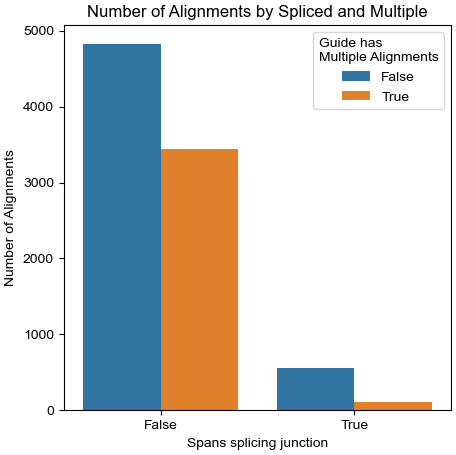

In [99]:
# Observations:
tdf = samfile_df.value_counts(["is_spliced", "multiple"]).reset_index()
fig, ax = pl.subplots(figsize=(5, 5))

sns.barplot(data=tdf, x="is_spliced", y="count", hue="multiple")
ax.set_ylabel("Number of Alignments")
ax.set_xlabel("Spans splicing junction")
ax.set_title("Number of Alignments by Spliced and Multiple")
ax.legend(title="Guide has\nMultiple Alignments", loc="upper right")
pl.show()

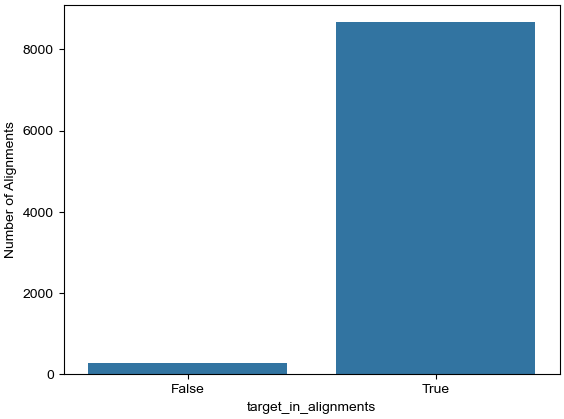

In [107]:
tdf = samfile_df.value_counts(["target_in_alignments"]).reset_index()
sns.barplot(data=tdf, y="count", x="target_in_alignments")
pl.ylabel("Number of Alignments")
pl.show()


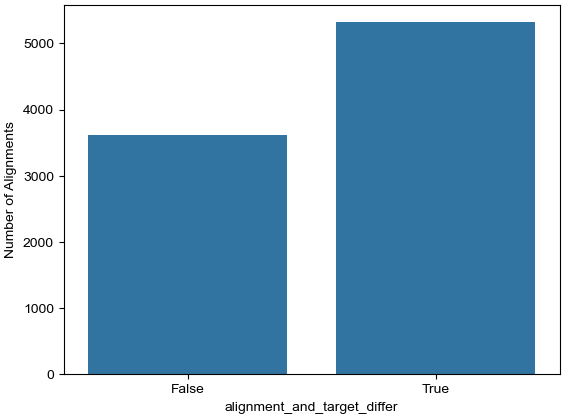

In [108]:
tdf = samfile_df.value_counts(["alignment_and_target_differ"]).reset_index()
sns.barplot(data=tdf, y="count", x="alignment_and_target_differ")
pl.ylabel("Number of Alignments")
pl.show()


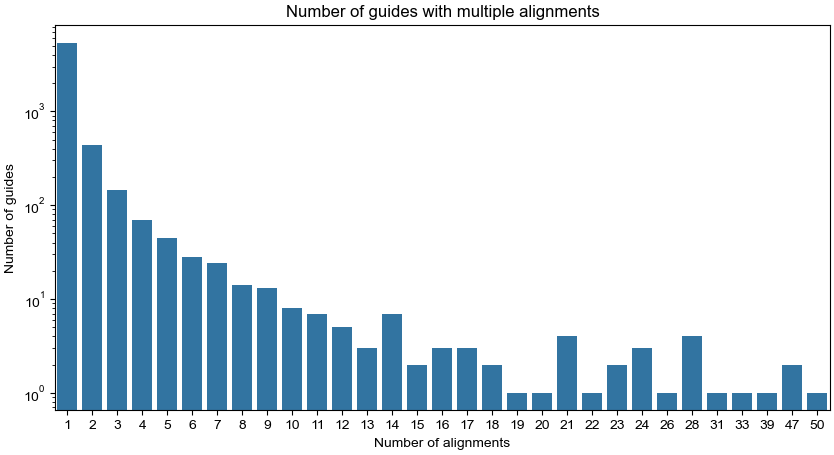

In [19]:
number_of_alignments = samfile_df.qname.value_counts().value_counts()
number_of_alignments.name = "number_of_guides"
number_of_alignments.index.name = "number_of_alignments"
number_of_alignments = number_of_alignments.reset_index()

fig, ax = pl.subplots(figsize=(10, 5))
sns.barplot(data=number_of_alignments.reset_index(), x="number_of_alignments", y="number_of_guides", ax=ax)
ax.set_yscale("log")
ax.set_xlabel("Number of alignments")
ax.set_ylabel("Number of guides")
ax.set_title("Number of guides with multiple alignments")
pl.show()

In [20]:
samfile_df.splice_junction.value_counts()

splice_junction
Not junctional    8271
Exon <- Exon       332
Exon -> Exon       311
Exon <- Intron      13
Intron -> Exon      10
Name: count, dtype: int64

In [36]:
# Are any NT guides aligning?
samfile_df[samfile_df.qname.str.contains("NT_Control")].flag.value_counts()

flag
4    100
Name: count, dtype: int64

In [37]:
weird_NT_guides = [
    'NT_Control_rc_000138_NA',
    'NT_Control_rc_000834_NA',
    'NT_Control_rc_000481_NA',
]
# nope, they don't map at all
samfile_df[samfile_df.qname.isin(weird_NT_guides)]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction
8842,NT_Control_rc_000481_NA,4,NaN,0,+,NaN,0,CGCCTGGACCAACCGAGAACATC,NaN,NaN,NaN,False,False,Not junctional
8911,NT_Control_rc_000138_NA,4,NaN,0,+,NaN,0,CATCCGCCCTGAATATTCACAAT,NaN,NaN,NaN,False,False,Not junctional
8931,NT_Control_rc_000834_NA,4,NaN,0,+,NaN,0,GATGTCGTTGAACCGATTGTTAC,NaN,NaN,NaN,False,False,Not junctional


In [39]:
samfile_df[(samfile_df.is_spliced)]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction
201,RPS29_ENST00000245458_213,0,chr14,49583655,+,21M2274N2M,60,AAGGAAGAGCATTTAGTCCAACT,0.0,1.0,0.0,True,False,Exon -> Exon
477,CENPX_ENST00000306704_254,0,chr17,82019200,+,20M73N3M,60,GATCCCTAGAAGTCCAGGAGCAG,0.0,1.0,0.0,True,False,Exon -> Exon
763,HNRNPD_ENST00000353341_1281,0,chr4,82354133,+,22M1149N1M,1,TTGGAAAATACTGCTTCACCACC,0.0,2.0,0.0,True,True,Exon -> Exon
764,HNRNPD_ENST00000353341_1281,256,chr4,82354133,+,22M740N1M,1,TTGGAAAATACTGCTTCACCACC,0.0,2.0,0.0,True,True,Exon -> Exon
1190,MRPL23_ENST00000397298_597,16,chr11,1956448,-,1M93N22M,60,GGTGGGCAGCTGTGGCAGAGCAG,0.0,1.0,0.0,True,False,Exon <- Exon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8701,GAPLINC_ENST00000581442_299,272,chr18,3467202,-,2M11552N21M,1,AGGGTATGCACAGATGTGGAAAC,0.0,4.0,0.0,True,True,Exon <- Exon
8702,GAPLINC_ENST00000581442_299,272,chr18,3467295,-,2M11459N21M,1,AGGGTATGCACAGATGTGGAAAC,0.0,4.0,0.0,True,True,Exon <- Exon
8731,CDKN2B-AS1_ENST00000583719_390,16,chr9,21995158,-,4M51589N19M,60,CTAGTGTCCCTTTTGATGAGAAG,0.0,1.0,0.0,True,False,Exon <- Exon
8807,ZEB1-AS1_ENST00000607166_136,0,chr10,31318540,+,1M355N22M,1,CCTTTCCAACTCCGACAGCCCGT,0.0,2.0,0.0,True,True,Exon -> Exon


In [129]:
samfile_df[(samfile_df.multiple)]

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments,is_sym10x1
5,PHF5A_ENST00000216252_825,0,chr2,168231503,+,23M,1,GTTCCTCAAGGACAGCTGCCACC,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True,True,False
6,PHF5A_ENST00000216252_825,256,chr22,41459978,+,23M,1,GTTCCTCAAGGACAGCTGCCACC,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True,True,False
13,PHF5A_ENST00000216252_590,0,chr22,41460213,+,23M,1,AATCCTTTTCCATCCCTACCACG,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True,True,False
14,PHF5A_ENST00000216252_590,256,chr2,168231738,+,23M,1,AATCCTTTTCCATCCCTACCACG,0.0,2.0,0.0,False,True,Not junctional,ACO2;PHF5A;STK39,PHF5A,True,True,False
17,ST13_ENST00000216218_2059,16,chr20,22273446,-,23M,1,TCCTGATGCATTTTGACTTGTCT,0.0,3.0,0.0,False,True,Not junctional,ENSG00000225170;LINC01427;ST13,ST13,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8815,FTX_ENST00000603037_2149,272,chr20,2778827,-,23M,1,TGCTGGGTCATATTGTAATTCTG,0.0,3.0,0.0,False,True,Not junctional,FTX;SPC25,FTX,True,True,False
8816,FTX_ENST00000603037_2149,256,chrX,74201977,+,23M,1,CAGAATTACAATATGACCCAGCA,0.0,3.0,0.0,False,True,Not junctional,FTX;SPC25,FTX,True,True,False
8822,FTX_ENST00000603037_2150,0,chr2,168874340,+,23M,1,ACAGAATTACAATATGACCCAGC,0.0,3.0,0.0,False,True,Not junctional,FTX;SPC25,FTX,True,True,False
8823,FTX_ENST00000603037_2150,256,chrX,74201976,+,23M,1,ACAGAATTACAATATGACCCAGC,0.0,3.0,0.0,False,True,Not junctional,FTX;SPC25,FTX,True,True,False


In [133]:
# Summaries per guides
cts = samfile_df.value_counts(["qname", "is_spliced", "multiple", 'alignment_on_gene', 'alignment_and_target_differ', 'target_in_alignments'], dropna=False).reset_index()
assert len(cts) == len(samfile_df.qname.unique()), "Very inconvenient"
cts.drop(columns=["count"], inplace=True)
cts.to_csv("../results/tables/guide_splice_junctions_summaries.csv", index=False)

In [134]:
# Find genes with guides that have different properties (spliced, multiple)
samfile_df['target'] = samfile_df.qname.str.split("_").str[0]
n_different_guides = samfile_df.value_counts(["target", "is_spliced", "multiple"], dropna=False, sort=False).reset_index().value_counts('target')

In [135]:
n_different_guides

target
HMGN3      4
RPL41      4
ZFAND6     4
GAS5       4
HNRNPD     4
          ..
MGAT2      1
MFAP3      1
METTL18    1
METTL14    1
ZSWIM3     1
Name: count, Length: 734, dtype: int64

In [136]:
# Are sym10x1 guides affected?

In [137]:
samfile_df

,qname,flag,chrom,pos,strand,cigar,mapq,seq,nm,nh,as,is_spliced,multiple,splice_junction,alignment_on_gene,guide_target,alignment_and_target_differ,target_in_alignments,is_sym10x1,target
0,MRPS35_ENST00000081029_1383,16,chr12,27755768,-,23M,60,AAGCTGGCATTTCAGTAGTTGCT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True,False,MRPS35
1,CYP26B1_ENST00000001146_4708,0,chr2,72129262,+,23M,60,AAGCCTATAGAAGAGCCACATTG,0.0,1.0,0.0,False,False,Not junctional,CYP26B1,CYP26B1,False,True,False,CYP26B1
2,LGALS1_ENST00000215909_508,16,chr22,37679732,-,23M,60,TGTGTGGCCTTTGACTGAAATCA,0.0,1.0,0.0,False,False,Not junctional,LGALS1,LGALS1,False,True,False,LGALS1
3,MRPS35_ENST00000081029_1602,16,chr12,27755987,-,23M,60,TAGCATCCTACTTTCTAGATTGT,0.0,1.0,0.0,False,False,Not junctional,MRPS35,MRPS35,False,True,False,MRPS35
4,MYH9_ENST00000216181_7048,0,chr22,36281734,+,23M,60,ACTATACTGAGTCAACGGTGCAG,0.0,1.0,0.0,False,False,Not junctional,MYH9,MYH9,False,True,False,MYH9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8932,NT_Control_rc_001000_NA,4,NaN,0,+,NaN,0,ATCTCGAGTACTGTGCGTCCGCA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False,False,NT
8933,NT_Control_rc_000290_NA,4,NaN,0,+,NaN,0,CTGCCGGACGGTTCAACTTGCGA,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False,False,NT
8934,NT_Control_rc_000603_NA,4,NaN,0,+,NaN,0,GGCTCATATACTCCGTGTCGAGT,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False,False,NT
8935,NT_Control_rc_000800_NA,4,NaN,0,+,NaN,0,GCGAATCCTTTCATCGGCCCTCC,NaN,NaN,NaN,False,False,Not junctional,NaN,NT,True,False,False,NT
